# Customer Segmentation: RFM and Clustering that Drives Action

**What you'll learn**

- How to start segmentation from the *action*, not the algorithm — and the four criteria
  (distinct, sizable, actionable, stable) that separate a useful segmentation from a
  pretty scatter plot.
- RFM scoring end-to-end on simulated transactions: quintile scores, the classic named
  segments (Champions, Loyal, At-risk, Hibernating), and one concrete action per segment —
  the no-ML workhorse that ships in a week.
- K-means done right: why a handful of whales destroys clustering on raw monetary values
  (demonstrated, then fixed with log transforms + standardization), and the honest truth
  about elbow/silhouette — they rarely agree, and interpretability breaks the tie.
- GMM vs k-means: soft assignments and elliptical clusters, with a demo of exactly when the
  difference matters and when it's a distinction without a difference.
- The null-clustering trap: k-means returns k confident clusters on pure noise. We guard
  with a gap-statistic-style reference comparison and bootstrap stability (re-cluster
  resamples, measure ARI).
- Profiling and naming clusters into a segment playbook, the distance-concentration caveat
  in high dimensions, and the senior judgment call: when you have an outcome, *model it* —
  clustering is not a targeting model.

**Why it matters in interviews**

- "Marketing wants 5 customer personas — walk me through how you'd build them" is a staple
  senior analytics case. The signal is whether you start from the action and validate that
  segments are real, not whether you can call `KMeans.fit`.
- "How do you choose k?" is a trap question: reciting the elbow method is a mid-level
  answer; the senior answer involves stability, reference nulls, and business constraints.
- "How do you know your clusters aren't just noise?" separates candidates who have shipped
  segmentation from those who ran a tutorial — most tutorials never mention that k-means
  *always* returns k clusters.
- Segmentation questions are often a disguised test of tool selection: knowing when the
  right answer is "don't cluster — build a supervised model" is a strong senior signal.

Related notebooks: churn as an outcome to model directly in
[02_churn_survival.ipynb](./02_churn_survival.ipynb), customer value in
[03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb), and targeting on *incremental* response in
[../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

## 1. Segmentation FOR WHAT? The action comes first

"Segment our customers" is not a task; it's a symptom of a missing sentence. The full
sentence is: *"segment our customers so that __team__ can do __action__ differently per
segment."* The blank determines everything downstream — the unit of analysis, the
features, the number of segments, and the algorithm (often: no algorithm at all).

| Consumer of the segmentation | Action it drives | What that implies |
|---|---|---|
| Lifecycle marketing | Different email/push cadence and offers per segment | Behavioral features (recency, frequency, spend); segments must map to *messages*; 4–8 segments max (each needs a creative + a journey) |
| Pricing / offers | Differentiated discounts, bundles | Willingness-to-pay proxies, price sensitivity; legal/fairness review; beware using protected attributes even indirectly |
| Product strategy | Roadmap bets, personas for design | Needs-based or usage-pattern features; stability over quarters matters more than micro-accuracy |
| Sales (B2B) | Account tiering, coverage model | Firmographics + usage; usually rule-based tiers, not clusters |

**The four criteria for a useful segment** (test every segmentation against these):

1. **Distinct** — segments differ *on the features that drive the action*, not just
   statistically. If two segments get the same email, merge them.
2. **Sizable** — big enough to justify differentiated treatment. A brilliant segment of
   0.4% of customers is a fun fact, not a strategy (exception: whales, where 0.4% of
   customers can be 30% of revenue — size in *value*, not just count).
3. **Actionable** — you can (a) identify members in production systems and (b) actually do
   something different for them. "Curious browsers" is not actionable if you can't score a
   customer into it at campaign time.
4. **Stable** — the segmentation survives resampling (it's structure, not noise) and
   doesn't churn wildly month to month. Marketing cannot re-learn five new personas every
   quarter.

We'll operationalize *distinct* with profiling (Section 7), *sizable* with segment
summaries, *actionable* with an action table, and *stable* with bootstrap ARI and a
temporal migration check (Sections 6 and 9).

## 2. Simulated transactions with known ground truth

We simulate an e-commerce customer base with **four latent behavioral archetypes** (so we
can later check whether RFM and clustering *recover* them — simulation-first, per the lab
style) plus a handful of **whale accounts** (B2B resellers with ~40x order values). Two
years of transaction history; the snapshot date is day 730.

- `champion`: frequent buyer (~2 orders/month), still active, ~$75 average order value (AOV)
- `regular`: steady buyer (~0.6/month), still active, ~$45 AOV
- `one_off`: bought once or twice around signup during a promo, ~$22 AOV, gone
- `lapsed_big`: was a strong buyer in year 1 (~$60 AOV), stopped 6–16 months ago

In [2]:
HORIZON = 730  # snapshot day
n_customers = 6000

# name, share, signup window, active-end rule, orders per 30 days, log-AOV mean, log-AOV sd
specs = [
    ("champion",   0.12, (0, 500), lambda s: np.full(len(s), float(HORIZON)), 2.0, np.log(75), 0.50),
    ("regular",    0.30, (0, 600), lambda s: np.full(len(s), float(HORIZON)), 0.6, np.log(45), 0.50),
    ("one_off",    0.35, (0, 700), lambda s: np.minimum(s + rng.exponential(40, len(s)), HORIZON), 1.2, np.log(22), 0.60),
    ("lapsed_big", 0.23, (0, 200), lambda s: rng.uniform(250, 550, len(s)), 1.3, np.log(60), 0.50),
]

counts = rng.multinomial(n_customers, [s[1] for s in specs])
cust_frames, cid0 = [], 0
for (name, _, (lo, hi), end_fn, rate30, aov_mu, aov_sd), n_arch in zip(specs, counts):
    signup = rng.uniform(lo, hi, n_arch)
    end = end_fn(signup)
    n_orders = rng.poisson(rate30 * (end - signup) / 30.0)
    if name == "one_off":
        n_orders = np.maximum(n_orders, 1)
    cust_frames.append(pd.DataFrame({
        "customer_id": np.arange(cid0, cid0 + n_arch), "archetype": name,
        "signup": signup, "active_end": end, "n_orders": n_orders,
        "aov_mu": aov_mu, "aov_sd": aov_sd,
    }))
    cid0 += n_arch
customers = pd.concat(cust_frames, ignore_index=True)

# Whales: 15 B2B reseller accounts hiding among champions/regulars, ~25-60x order values
whale_ids = rng.choice(
    customers.loc[customers["archetype"].isin(["champion", "regular"]), "customer_id"].to_numpy(),
    size=15, replace=False)
customers["is_whale"] = customers["customer_id"].isin(whale_ids)
customers.loc[customers["is_whale"], "aov_mu"] += np.log(rng.uniform(25, 60, 15))

# Explode to a transaction table
rep = customers.loc[customers["n_orders"] > 0].reset_index(drop=True)
idx = np.repeat(rep.index.to_numpy(), rep["n_orders"].to_numpy())
tx = pd.DataFrame({
    "customer_id": rep.loc[idx, "customer_id"].to_numpy(),
    "day": rng.uniform(rep.loc[idx, "signup"].to_numpy(), rep.loc[idx, "active_end"].to_numpy()),
    "value": rng.lognormal(rep.loc[idx, "aov_mu"].to_numpy(), rep.loc[idx, "aov_sd"].to_numpy()),
})
print(f"{len(tx):,} transactions from {tx['customer_id'].nunique():,} purchasing customers "
      f"(of {n_customers:,} signups; zero-purchase customers are invisible to RFM)")
print(f"revenue share of the {len(whale_ids)} whales: "
      f"{tx.loc[tx['customer_id'].isin(whale_ids), 'value'].sum() / tx['value'].sum():.1%}")
tx.head()

59,716 transactions from 5,986 purchasing customers (of 6,000 signups; zero-purchase customers are invisible to RFM)
revenue share of the 15 whales: 17.2%


,customer_id,day,value
0,0,645.184,34.276
1,0,398.277,37.298
2,0,641.331,83.314
3,0,425.152,164.332
4,0,680.465,133.247


## 3. RFM: the no-ML workhorse

Before any clustering, build **RFM** — for each customer as of the snapshot date:
**Recency** (days since last purchase), **Frequency** (number of orders), **Monetary**
(total spend; average order value is a legitimate alternative — see Exercise 1). Score each
dimension into quintiles (5 = best), then map score combinations to named segments with an
owner and an action. This is deterministic, explainable to marketing in one meeting,
trivially reproducible in SQL, and captures most of the lifecycle signal. **Ship this
first**; cluster later only if you need patterns RFM can't express.

Implementation notes that bite in practice:
- Frequency is heavily tied (many customers with 1–2 orders), so naive `qcut` fails —
  rank first (`rank(method="first")`), or use fixed business cutoffs.
- Recency is scored *reversed*: small recency = recently active = score 5.
- RFM only sees *buyers*. Registered-but-never-purchased users need a separate track.

In [3]:
rfm = (tx.groupby("customer_id")
         .agg(last_day=("day", "max"), frequency=("day", "size"), monetary=("value", "sum")))
rfm["recency"] = HORIZON - rfm["last_day"]
rfm = (rfm.drop(columns="last_day")
          .join(customers.set_index("customer_id")[["archetype", "is_whale"]]))

rfm["R"] = 5 - pd.qcut(rfm["recency"], 5, labels=False)                       # low recency -> 5
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=False) + 1
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=False) + 1

def rfm_segment(r, f):
    """Classic RFM grid on the R and F scores (M is used for prioritization within segment)."""
    if r >= 4 and f >= 4: return "Champions"
    if r >= 3 and f >= 3: return "Loyal"
    if r >= 4:            return "Recent / promising"
    if r == 3:            return "About to sleep"
    if f >= 4:            return "At risk - can't lose"
    if f == 3:            return "At risk"
    return "Hibernating"

rfm["segment"] = [rfm_segment(r, f) for r, f in zip(rfm["R"], rfm["F"])]

seg_order = ["Champions", "Loyal", "Recent / promising", "About to sleep",
             "At risk - can't lose", "At risk", "Hibernating"]
seg_summary = (rfm.groupby("segment")
                  .agg(n=("segment", "size"), recency_med=("recency", "median"),
                       freq_med=("frequency", "median"), monetary_med=("monetary", "median"),
                       revenue=("monetary", "sum"))
                  .reindex(seg_order))
seg_summary["pct_customers"] = seg_summary["n"] / len(rfm) * 100
seg_summary["pct_revenue"] = seg_summary["revenue"] / rfm["monetary"].sum() * 100
print(seg_summary.drop(columns="revenue").round(1))

                         n  recency_med  freq_med  monetary_med  pct_customers  pct_revenue
segment                                                                                    
Champions             1257         15.3      19.0        1416.1           21.0         62.0
Loyal                 1200         72.4       8.0         427.4           20.0         16.2
Recent / promising     485         39.3       3.0          95.5            8.1          1.5
About to sleep         650        163.2       1.0          32.4           10.9          0.7
At risk - can't lose   743        352.2      14.0         926.9           12.4         15.1
At risk                391        440.1       7.0         394.9            6.5          3.2
Hibernating           1260        479.0       1.0          30.6           21.0          1.3


### One action per segment — or the segmentation is decoration

| Segment | Who they are | Action (owner: lifecycle marketing) |
|---|---|---|
| Champions | recent + frequent | Early access, referral program, ask for reviews. **No discounts** — don't pay for behavior you already get. |
| Loyal | steady, engaged | Cross-sell adjacent categories; loyalty tier upsell. |
| Recent / promising | new-ish, low frequency so far | Onboarding series toward 2nd/3rd purchase (the biggest retention cliff). |
| About to sleep | cooling off | Reminder + light incentive now; cheap to save today, expensive in 90 days. |
| At risk - can't lose | high historical value, gone quiet | High-touch win-back: personal outreach, meaningful offer; investigate *why* (support tickets, price change?). |
| At risk | mid value, lapsing | Standard win-back journey; cap spend by expected LTV ([03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb)). |
| Hibernating | long gone, low value | Cheap reactivation at most; mostly *suppress* — stop paying to email the dead, protect deliverability. |

The sanity check below: does this purely-heuristic grid recover the latent archetypes we
simulated? Largely yes — champions land in Champions/Loyal, `lapsed_big` lands in the
at-risk family, `one_off` in Hibernating. RFM earns its keep before any ML shows up.

Latent archetype vs RFM segment (row %):
segment     Champions  Loyal  Recent / promising  About to sleep  At risk - can't lose  At risk  Hibernating
archetype                                                                                                   
champion         99.0    1.0                 0.0             0.0                   0.0      0.0          0.0
lapsed_big        0.0   22.0                 0.0             0.0                  53.0     21.0          4.0
one_off           0.0    3.0                10.0            26.0                   0.0      5.0         55.0
regular          33.0   47.0                15.0             5.0                   0.0      0.0          0.0


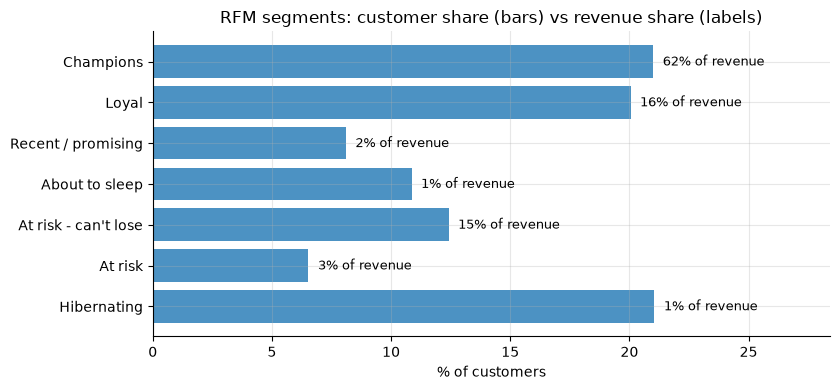

In [4]:
print("Latent archetype vs RFM segment (row %):")
ct = pd.crosstab(rfm["archetype"], rfm["segment"], normalize="index") * 100
print(ct[[c for c in seg_order if c in ct.columns]].round(0))

fig, ax = plt.subplots(figsize=(8.5, 4.0))
s = seg_summary.iloc[::-1]
bars = ax.barh(s.index, s["pct_customers"], color="tab:blue", alpha=0.8)
for bar, (_, row) in zip(bars, s.iterrows()):
    ax.annotate(f"{row['pct_revenue']:.0f}% of revenue",
                (bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2),
                va="center", fontsize=9)
ax.set_xlabel("% of customers")
ax.set_title("RFM segments: customer share (bars) vs revenue share (labels)")
ax.set_xlim(0, s["pct_customers"].max() * 1.35)
plt.show()

## 4. K-means done right

Now suppose we want data-driven segments on the continuous (recency, frequency, monetary)
space instead of a hand-made grid. K-means is the default — and the default way to run it
is wrong.

### 4.1 The whale trap: skewed features eat your clusters

Monetary value is extremely right-skewed (15 whales hold a double-digit revenue share).
K-means minimizes *squared* Euclidean distance, so a point 40 standard deviations out
contributes 1600x its share of the objective. Standardizing does **not** fix this —
dividing by a whale-inflated standard deviation just compresses everyone else toward zero.
Watch what happens on standardized-but-raw features:

In [5]:
feat_raw = rfm[["recency", "frequency", "monetary"]]
X_rawstd = StandardScaler().fit_transform(feat_raw)
km_raw = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_rawstd)

raw_prof = feat_raw.assign(cluster=km_raw.labels_, whale=rfm["is_whale"]).groupby("cluster").agg(
    n=("cluster", "size"), whales=("whale", "sum"),
    monetary_median=("monetary", "median"), monetary_max=("monetary", "max"))
print("k-means on standardized RAW features:")
print(raw_prof.round(0))
print(f"\nARI vs latent archetypes: {adjusted_rand_score(rfm['archetype'], km_raw.labels_):.3f}")

k-means on standardized RAW features:
            n  whales  monetary_median  monetary_max
cluster                                             
0         688       3           2678.0       29326.0
1        2313       0             93.0        1782.0
2           7       7          90618.0      162441.0
3        2978       4            347.0       15113.0

ARI vs latent archetypes: 0.319


One "cluster" is a whale enclosure with a handful of members, and the remaining thousands
of customers get mushed into the leftover clusters — the monetary axis is spent entirely on
separating 15 accounts. (A tiny cluster like this *is* useful output — as an **anomaly
list** for the key-accounts team, not as a marketing segment. Route the whales to a named
list, then segment everyone else.)

**The fix**: `log1p` the skewed count/amount features so multiplicative differences become
additive ($20 vs $200 is the same distance as $200 vs $2,000 — which matches business
intuition about customer similarity), *then* standardize so each feature contributes
comparably. Recency is bounded and only mildly skewed; we leave it linear here.

cluster sizes (log-transformed features): [1368 1162 1395 2061]
ARI vs latent archetypes  raw: 0.319   log: 0.488


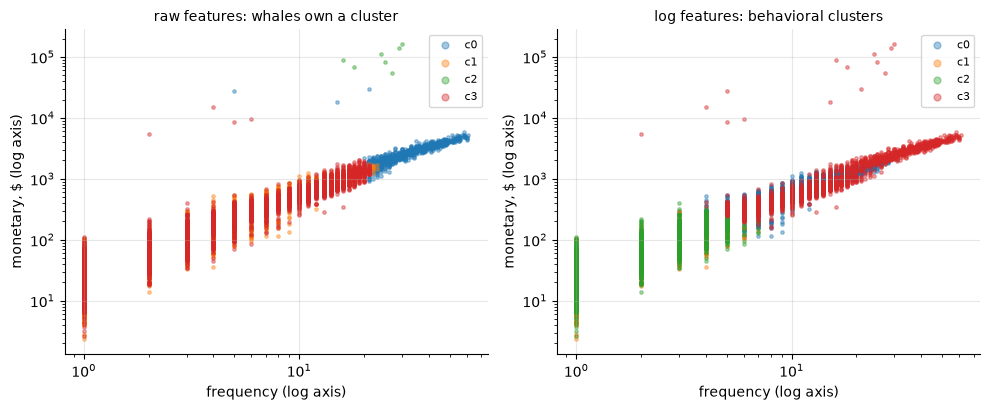

In [6]:
feat = pd.DataFrame({
    "recency": rfm["recency"],
    "log_frequency": np.log1p(rfm["frequency"]),
    "log_monetary": np.log1p(rfm["monetary"]),
}, index=rfm.index)
scaler = StandardScaler().fit(feat)
X = scaler.transform(feat)
km_log = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)

print("cluster sizes (log-transformed features):", np.bincount(km_log.labels_))
print(f"ARI vs latent archetypes  raw: {adjusted_rand_score(rfm['archetype'], km_raw.labels_):.3f}"
      f"   log: {adjusted_rand_score(rfm['archetype'], km_log.labels_):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=False)
for ax, labels, title in [(axes[0], km_raw.labels_, "raw features: whales own a cluster"),
                          (axes[1], km_log.labels_, "log features: behavioral clusters")]:
    for c in range(4):
        m = labels == c
        ax.scatter(feat_raw["frequency"][m], feat_raw["monetary"][m], s=6, alpha=0.4, label=f"c{c}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("frequency (log axis)"); ax.set_ylabel("monetary, $ (log axis)")
    ax.set_title(title, fontsize=10)
    ax.legend(markerscale=2, fontsize=8)
plt.show()

The ARI against the (normally unobservable) ground truth confirms it: log-transforming
lifts agreement with the true archetypes by roughly half. In real data you don't get an ARI
oracle — the observable symptoms of the whale trap are **tiny clusters**, cluster profiles
that differ only on the skewed feature, and centroids dragged far from medians.

### 4.2 Choosing k: elbow and silhouette, with the honest take

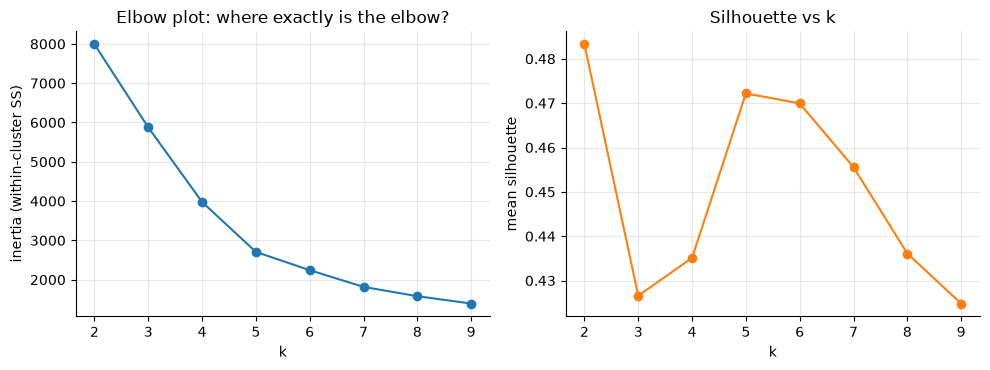

silhouette argmax: k=2;  silhouette values for k=2..9: 0.483, 0.427, 0.435, 0.472, 0.470, 0.456, 0.436, 0.425


In [7]:
ks = range(2, 10)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(list(ks), inertia, "o-")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia (within-cluster SS)")
axes[0].set_title("Elbow plot: where exactly is the elbow?")
axes[1].plot(list(ks), sil, "o-", color="tab:orange")
axes[1].set_xlabel("k"); axes[1].set_ylabel("mean silhouette")
axes[1].set_title("Silhouette vs k")
plt.show()
best_k_sil = list(ks)[int(np.argmax(sil))]
print(f"silhouette argmax: k={best_k_sil};  silhouette values for k=2..9: "
      + ", ".join(f"{s:.3f}" for s in sil))

**The honest take** — and the answer interviewers actually want: these diagnostics rarely
produce one crisp answer, *even here*, on simulated data with exactly 4 planted
archetypes. The elbow bends gradually; silhouette tends to favor coarse splits (a low k
that just separates "active vs inactive") because the archetypes genuinely overlap in RFM
space, and differences between neighboring k are small. That is the normal situation with
real behavioral data, which contains continuous gradients, not billiard-ball clusters.

So treat elbow/silhouette as **range-finders, not deciders**: they narrow k to a plausible
range (here roughly 3–6). Within that range the tie-breakers are:
1. **Interpretability** — can you name every cluster in one line? A cluster you can't name
   is a cluster marketing can't use (Section 7).
2. **Stability** — does k survive bootstrap re-clustering (Section 6)?
3. **Operational capacity** — how many differentiated treatments can the team actually run?
   That number is usually 4–8 and is a *constraint*, not a nuisance.

## 5. GMM vs k-means: soft assignments and elliptical clusters

K-means is (in the model-based view) a degenerate Gaussian mixture: spherical clusters,
equal covariance, **hard** assignments. A Gaussian Mixture Model relaxes all three: full
covariance ellipses and posterior membership *probabilities*. Two situations where that
matters:

1. **Elongated / correlated clusters.** Behavioral features are correlated (tenure and
   total spend; sessions and orders). K-means slices across elongated clusters because it
   can only draw spherical boundaries.
2. **Boundary customers.** Hard assignment hides that many customers sit between segments.
   A posterior of (0.51 Loyal, 0.49 At-risk) and one of (0.99 Loyal, 0.01) get identical
   treatment under k-means — but you might want to hold out ambiguous customers or give
   them the cheaper of two treatments.

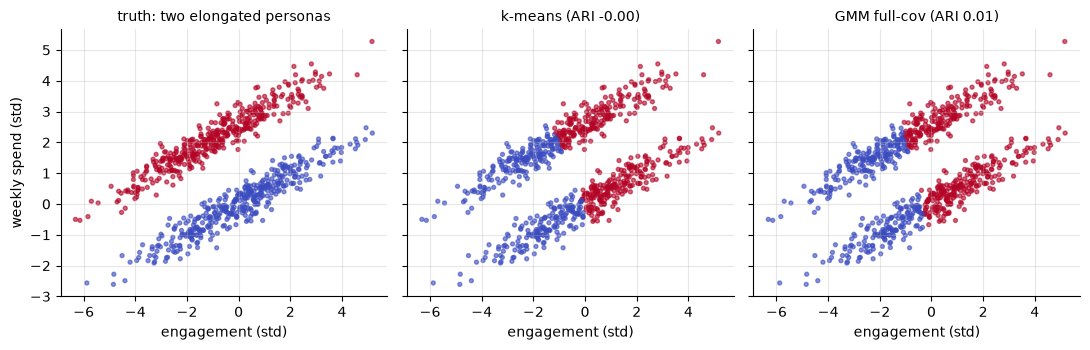

In [8]:
# Two elongated, correlated "personas": engagement vs spend, offset perpendicular to the trend
n_demo = 400
cov = np.array([[4.0, 1.9], [1.9, 1.0]])
A = rng.multivariate_normal([0, 0], cov, n_demo)
B = rng.multivariate_normal([-1.0, 2.1], cov, n_demo)
X_demo = np.vstack([A, B])
y_demo = np.repeat([0, 1], n_demo)

km_d = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_demo)
gm_d = GaussianMixture(n_components=2, covariance_type="full", n_init=3, random_state=42).fit(X_demo)
lab_gm = gm_d.predict(X_demo)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], y_demo, "truth: two elongated personas"),
                       (axes[1], km_d.labels_, f"k-means (ARI {adjusted_rand_score(y_demo, km_d.labels_):.2f})"),
                       (axes[2], lab_gm, f"GMM full-cov (ARI {adjusted_rand_score(y_demo, lab_gm):.2f})")]:
    ax.scatter(X_demo[:, 0], X_demo[:, 1], c=lab, cmap="coolwarm", s=8, alpha=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("engagement (std)")
axes[0].set_ylabel("weekly spend (std)")
plt.show()

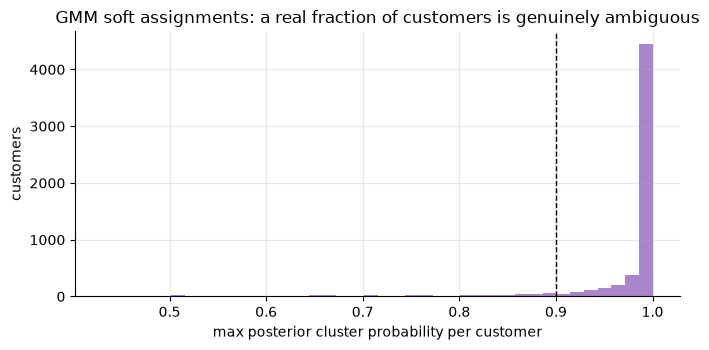

customers with max posterior < 0.9: 9.8%   (< 0.6: 1.7%)
agreement of GMM hard labels with k-means labels (ARI): 0.547


In [9]:
# GMM on the customer RFM features: how many customers are actually ambiguous?
gmm = GaussianMixture(n_components=4, covariance_type="full", n_init=3, random_state=42).fit(X)
post = gmm.predict_proba(X)
max_post = post.max(axis=1)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(max_post, bins=40, color="tab:purple", alpha=0.8)
ax.axvline(0.9, color="k", ls="--", lw=1)
ax.set_xlabel("max posterior cluster probability per customer")
ax.set_ylabel("customers")
ax.set_title("GMM soft assignments: a real fraction of customers is genuinely ambiguous")
plt.show()
print(f"customers with max posterior < 0.9: {(max_post < 0.9).mean():.1%}"
      f"   (< 0.6: {(max_post < 0.6).mean():.1%})")
print(f"agreement of GMM hard labels with k-means labels (ARI): "
      f"{adjusted_rand_score(km_log.labels_, gmm.predict(X)):.3f}")

**When does the difference matter?**

- Use **GMM** when clusters are plausibly elongated/overlapping (they usually are in
  behavioral data), when you want membership *uncertainty* as a first-class output (e.g.,
  only send the aggressive win-back to customers who are ≥90% "at risk"), or when you want
  a generative density (GMM gives you `score_samples` for anomaly flagging free of charge).
- **K-means is fine** when clusters are compact and well separated, when you need to
  explain the method in one sentence, or at a scale where GMM's per-cluster covariance is
  too expensive. With well-separated blobs the two produce nearly identical partitions —
  check the ARI between them before arguing about which is "better."
- Interview nuance: GMM's k can be chosen with BIC/AIC because it's a proper likelihood
  model — but BIC optimizes *density fit*, not *segment usefulness*, and will happily add
  components to model skew in a single behavioral group (see Exercise 3).

## 6. The null-clustering trap: k-means always "finds" k clusters

The most important fact about k-means: **it is an optimizer, not a test.** Feed it
structureless noise and it will return k confident, tidy, plottable clusters — with
centroids, sizes, and a silhouette score — every single time. Here we run the *identical
pipeline* on a null dataset (each feature column independently permuted, which preserves
every marginal distribution but destroys all joint structure).

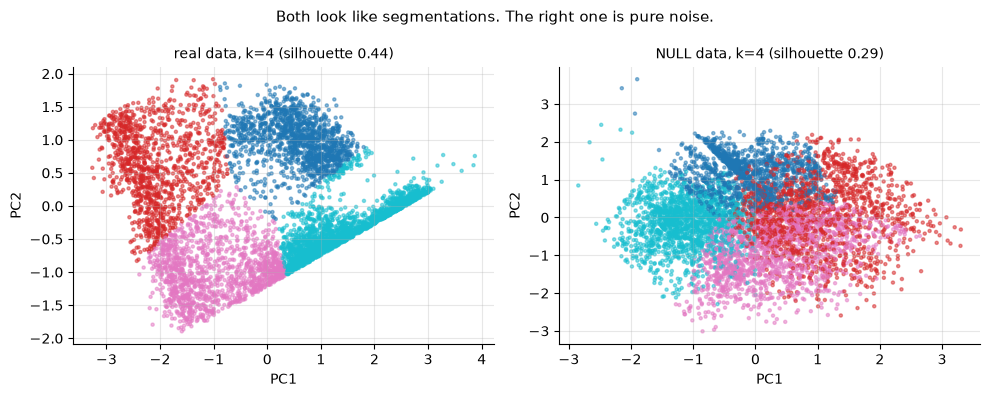

In [10]:
X_null = X.copy()
for j in range(X_null.shape[1]):
    X_null[:, j] = rng.permutation(X_null[:, j])

km_null = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_null)

pca = PCA(n_components=2, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
for ax, Xd, labels, title in [
        (axes[0], X, km_log.labels_, f"real data, k=4 (silhouette {silhouette_score(X, km_log.labels_):.2f})"),
        (axes[1], X_null, km_null.labels_, f"NULL data, k=4 (silhouette {silhouette_score(X_null, km_null.labels_):.2f})")]:
    Z = pca.fit_transform(Xd)
    ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=5, alpha=0.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.suptitle("Both look like segmentations. The right one is pure noise.", fontsize=11)
plt.show()

The null clustering *looks* like a deliverable — colored regions, nonzero silhouette.
Nothing in the k-means output warns you. You need external guards:

**Guard 1 — reference/null comparison (the gap-statistic idea).** Compare the within-
cluster dispersion $W(k)$ on your data against $W(k)$ on reference datasets with no joint
structure: $\text{gap}(k) = \mathbb{E}[\log W_{\text{ref}}(k)] - \log W_{\text{data}}(k)$.
Real structure makes $W_{\text{data}}(k)$ drop *much faster* than the reference as k grows,
so the gap opens up; on structureless data the gap hugs zero for all k. (Tibshirani's full
recipe adds a standard-error rule for picking k; the comparison itself is the load-bearing
part.)

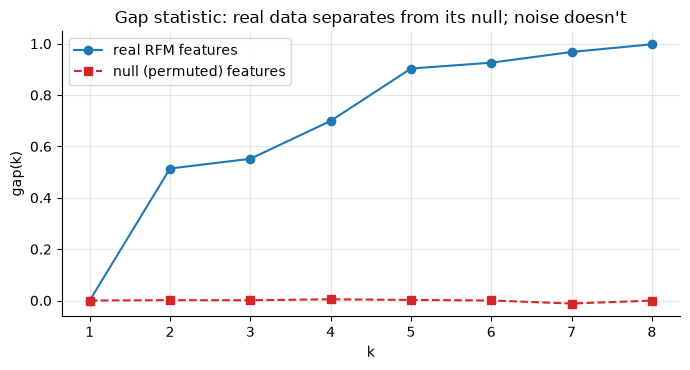

In [11]:
def gap_curve(Xd, ks, B=8, seed=0):
    """Gap statistic with column-permutation reference (preserves marginals)."""
    g = np.random.default_rng(seed)
    logW = np.array([np.log(KMeans(n_clusters=k, n_init=5, random_state=42).fit(Xd).inertia_)
                     for k in ks])
    logW_ref = np.zeros((B, len(ks)))
    for b in range(B):
        Xr = np.column_stack([g.permutation(Xd[:, j]) for j in range(Xd.shape[1])])
        logW_ref[b] = [np.log(KMeans(n_clusters=k, n_init=5, random_state=b).fit(Xr).inertia_)
                       for k in ks]
    return logW_ref.mean(axis=0) - logW

ks_gap = range(1, 9)
gap_real = gap_curve(X, ks_gap)
gap_null = gap_curve(X_null, ks_gap, seed=1)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(list(ks_gap), gap_real, "o-", label="real RFM features")
ax.plot(list(ks_gap), gap_null, "s--", color="tab:red", label="null (permuted) features")
ax.set_xlabel("k"); ax.set_ylabel("gap(k)")
ax.set_title("Gap statistic: real data separates from its null; noise doesn't")
ax.legend()
plt.show()

**Guard 2 — bootstrap stability (ARI).** If clusters reflect real structure, re-clustering
bootstrap resamples should keep producing *the same partition* of the original points.
Fit k-means on B resamples, assign every original point with each fitted model, and
measure pairwise **Adjusted Rand Index** between the B labelings. ARI near 1 = the
partition is a property of the population; ARI drifting toward 0 = the partition is a
property of the sample (noise). Rule of thumb (Hennig): mean stability below ~0.6 means
don't ship it; above ~0.8 is solid. One caveat to hold onto before the numbers appear:
stability is **necessary, not sufficient** — k-means can stably partition even
structureless data (quartering a round cloud is a very reproducible operation), so low
stability kills a segmentation, but high stability alone doesn't certify it.

In [12]:
def bootstrap_stability(Xd, k, B=10, seed=0):
    g = np.random.default_rng(seed)
    n = len(Xd)
    labelings = []
    for b in range(B):
        km = KMeans(n_clusters=k, n_init=5, random_state=b).fit(Xd[g.integers(0, n, n)])
        labelings.append(km.predict(Xd))
    return float(np.mean([adjusted_rand_score(labelings[i], labelings[j])
                          for i in range(B) for j in range(i + 1, B)]))

stab_real = bootstrap_stability(X, 4)
stab_null = bootstrap_stability(X_null, 4, seed=1)
print(f"bootstrap stability (mean pairwise ARI, k=4)   real: {stab_real:.3f}   null: {stab_null:.3f}")

bootstrap stability (mean pairwise ARI, k=4)   real: 0.969   null: 0.890


Notice what actually happened: the real data is near-perfectly stable (ARI ≈ 0.97), but
the null is *also* fairly stable (≈ 0.89). That is the caveat in action — column
permutation preserves every marginal, and our recency marginal is genuinely bimodal
(actives vs long-lapsed), so k-means can reproducibly split on that one axis even with all
joint structure destroyed. Two senior lessons: (1) stability **screens out** shaky
segmentations but cannot certify structure by itself — pair it with the gap/null
comparison, which is the discriminating guard here (the gap curves separate; the stability
numbers barely do); (2) your choice of null matters — a uniform reference (Tibshirani's
original) erases marginal structure too and punishes this null harder. Stability across k
remains a principled way to *choose among* candidate k values (Exercise 2).

## 7. Profiling and naming: from cluster IDs to a segment playbook

A cluster is not a segment until it has a **profile** (how it differs), a **name** (one
line, no jargon), and an **action** (who does what). Profile on the z-scored feature means
— and derive names *from the profile with explicit rules*, not from vibes, so the naming
survives a refit.

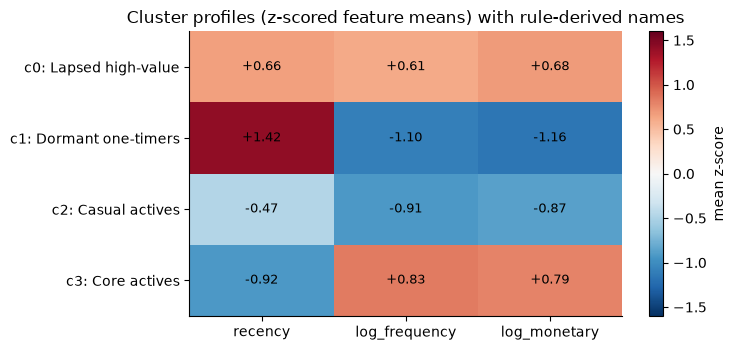

In [13]:
final_k = 4
final_km = KMeans(n_clusters=final_k, n_init=10, random_state=42).fit(X)
rfm["cluster"] = final_km.labels_

profile_z = pd.DataFrame(X, index=rfm.index, columns=feat.columns).groupby(rfm["cluster"]).mean()

def name_from_profile(z):
    """Rule-based naming on mean z-scores: recency high = long gone; frequency high = engaged."""
    if z["log_frequency"] > 0.35 and z["recency"] < 0:
        return "Core actives"
    if z["recency"] > 0.25 and z["log_monetary"] > 0:
        return "Lapsed high-value"
    if z["recency"] > 0.25:
        return "Dormant one-timers"
    return "Casual actives"

names = {}
for c, z in profile_z.iterrows():
    nm = name_from_profile(z)
    while nm in names.values():
        nm += " (b)"
    names[c] = nm
rfm["cluster_name"] = rfm["cluster"].map(names)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(profile_z.to_numpy(), cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(len(feat.columns)), feat.columns)
ax.set_yticks(range(final_k), [f"c{c}: {names[c]}" for c in profile_z.index])
for i in range(final_k):
    for j in range(len(feat.columns)):
        ax.annotate(f"{profile_z.iloc[i, j]:+.2f}", (j, i), ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="mean z-score")
ax.set_title("Cluster profiles (z-scored feature means) with rule-derived names")
ax.grid(False)
plt.show()

In [14]:
playbook = (rfm.groupby("cluster_name")
              .agg(n=("cluster_name", "size"), recency_med=("recency", "median"),
                   freq_med=("frequency", "median"), monetary_med=("monetary", "median"),
                   revenue=("monetary", "sum"))
              .sort_values("revenue", ascending=False))
playbook["pct_customers"] = playbook["n"] / len(rfm) * 100
playbook["pct_revenue"] = playbook["revenue"] / rfm["monetary"].sum() * 100
print(playbook.drop(columns="revenue").round(1))
print("\ncluster vs latent archetype (row %):")
print((pd.crosstab(rfm["cluster_name"], rfm["archetype"], normalize="index") * 100).round(0))

                       n  recency_med  freq_med  monetary_med  pct_customers  pct_revenue
cluster_name                                                                             
Core actives        2061         21.9      13.0         697.1           34.4         72.3
Lapsed high-value   1368        350.0      12.0         837.9           22.9         24.2
Casual actives      1395        110.8       2.0          53.9           23.3          2.4
Dormant one-timers  1162        501.4       1.0          30.6           19.4          1.1

cluster vs latent archetype (row %):
archetype           champion  lapsed_big  one_off  regular
cluster_name                                              
Casual actives           0.0         0.0     69.0     31.0
Core actives            34.0         3.0      1.0     62.0
Dormant one-timers       0.0         4.0     96.0      0.0
Lapsed high-value        0.0        93.0      5.0      1.0


The playbook translation (this table — not the scatter plot — is the deliverable):

| Cluster | Sizable? | Action | KPI to move |
|---|---|---|---|
| Core actives | yes — a third of customers, ~70% of revenue | Protect: loyalty benefits, early access, service SLAs; suppress discounts | retention rate, NPS |
| Casual actives | yes | Grow: cross-sell, 2nd-category adoption, subscription nudge | orders/customer/quarter |
| Lapsed high-value | yes; revenue-weighted very much so | Win-back with real investment, cap by expected LTV; root-cause the lapse | reactivation rate, recovered revenue |
| Dormant one-timers | largest by count, smallest by value | Cheap reactivation once, then suppress; fix top-of-funnel quality upstream | cost per reactivation |

Check the crosstab: the clusters largely rediscover the planted archetypes — and notice
k-means and the RFM grid of Section 3 tell *the same story*. That convergence is typical,
which is exactly why RFM ships first.

### 7.1 High-dimensional caveat: distance concentration

It's tempting to throw 40 behavioral features into the clustering. In high dimensions,
pairwise Euclidean distances **concentrate**: the relative gap between the nearest and
farthest point shrinks, so "closest centroid" becomes close to arbitrary and every
clustering algorithm built on distances degrades — silently.

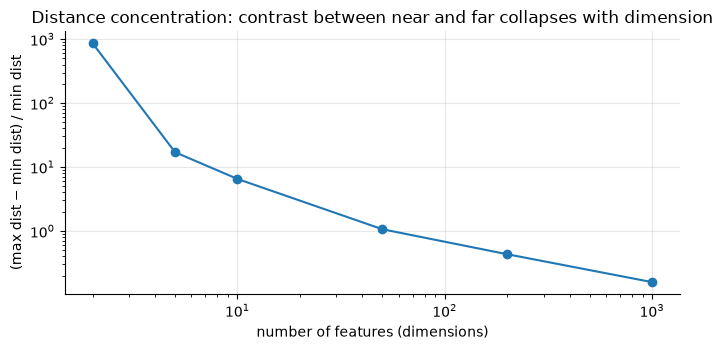

2       859.37
5        17.03
10        6.50
50        1.06
200       0.43
1000      0.16
Name: relative contrast, dtype: float64


In [15]:
dims = [2, 5, 10, 50, 200, 1000]
contrast = []
for d in dims:
    P = rng.uniform(size=(300, d))
    dist = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1))
    dist = dist[np.triu_indices(300, k=1)]
    contrast.append((dist.max() - dist.min()) / dist.min())

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(dims, contrast, "o-")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("number of features (dimensions)")
ax.set_ylabel("(max dist − min dist) / min dist")
ax.set_title("Distance concentration: contrast between near and far collapses with dimension")
plt.show()
print(pd.Series(contrast, index=dims, name="relative contrast").round(2))

Practical consequences for segmentation: keep the feature list **short and
action-relevant** (5–10 features chosen for the decision, not 50 chosen by availability);
decorrelate/compress first (PCA, or embeddings for event sequences) if you must use many;
and be suspicious of any clustering whose silhouette collapses when you add features —
that's concentration, not "the customers got less structured."

## 8. Clustering vs supervised targeting: if you have an outcome, model it

The most common senior-level misuse of clustering: using unsupervised segments to target an
action **whose outcome you can observe**. "We'll send the win-back offer to the At-risk
cluster." If you have (or can get) labels — responded, churned, converted — a supervised
model of that outcome will beat cluster-based targeting, because clustering optimizes
geometric compactness, not the outcome. Segments answer *"who are our customers?"*;
models answer *"who should get this intervention?"* Those are different questions.

Demo: simulate a win-back campaign where true response probability depends smoothly on
recency and frequency (as it would in reality — no cluster boundaries in sight), then
compare capture rates at the same contact budget.

In [16]:
# Ground-truth response model: recently-lapsed frequent buyers respond most
p_resp = expit(-1.8 + 0.75 * np.log1p(rfm["frequency"]) - 0.006 * rfm["recency"])
rfm["responded"] = rng.random(len(rfm)) < p_resp
print(f"overall response rate if everyone were contacted: {rfm['responded'].mean():.1%}")

train_idx, test_idx = train_test_split(np.arange(len(rfm)), test_size=0.5, random_state=42)
Xtr, Xte = X[train_idx], X[test_idx]
ytr = rfm["responded"].to_numpy()[train_idx]
yte = rfm["responded"].to_numpy()[test_idx]
clus_te = rfm["cluster"].to_numpy()[test_idx]

# Strategy A: coarse segments — fill a 20% budget best-cluster-first. Within a cluster
# there is NO ranking (that's what a hard segment means), so if the best cluster is bigger
# than the budget, the marketer contacts a random subset of it.
clus_tr = rfm["cluster"].to_numpy()[train_idx]
rate_by_cluster = pd.Series(ytr).groupby(clus_tr).mean().sort_values(ascending=False)
budget = int(0.20 * len(yte))
targeted_A = np.zeros(len(yte), dtype=bool)
for c in rate_by_cluster.index:
    members = np.flatnonzero(clus_te == c)
    room = budget - int(targeted_A.sum())
    if room <= 0:
        break
    if len(members) > room:
        members = rng.choice(members, size=room, replace=False)
    targeted_A[members] = True

# Strategy B: supervised model, top-budget customers by predicted response (same budget)
lr = LogisticRegression(random_state=42).fit(Xtr, ytr)
scores = lr.predict_proba(Xte)[:, 1]
targeted_B = np.zeros(len(yte), dtype=bool)
targeted_B[np.argsort(-scores)[:budget]] = True

comparison = pd.DataFrame({
    "contacts": [budget, budget, budget],
    "response rate in targeted": [yte[targeted_A].mean(), yte[targeted_B].mean(), yte.mean()],
    "share of all responders captured": [yte[targeted_A].sum() / yte.sum(),
                                         yte[targeted_B].sum() / yte.sum(),
                                         budget / len(yte)],
}, index=["A: best clusters (unsupervised)", "B: supervised model score", "random targeting"])
print(comparison.round(3))

overall response rate if everyone were contacted: 24.3%
                                 contacts  response rate in targeted  share of all responders captured
A: best clusters (unsupervised)       598                      0.500                             0.415
B: supervised model score             598                      0.589                             0.488
random targeting                      598                      0.241                             0.200


Same budget, same features — the supervised ranking wins because it can order customers
*within* the best cluster, whom segment-level targeting must treat as interchangeable. The
gap here is real but modest, because our simulated response happens to be smooth and
monotone in exactly the features the clusters split on; real response surfaces
(non-monotone in recency, interactions with category mix) widen it further, since coarse
cluster boundaries have no way to express them. And the demo still flatters clustering: we
let it rank clusters by observed training response, which is already half-supervised.

**Decision rule**: outcome observable → supervised model
(churn: [02_churn_survival.ipynb](./02_churn_survival.ipynb)); decision is about
*incremental* effect of the action → uplift/CATE modeling, because responders ≠ persuadables
([../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb));
no single outcome, or the goal is shared understanding, strategy, and creative
differentiation → segmentation. The strongest production pattern is layered: segments set
the *message and journey*; a supervised/uplift score decides *who* enters and at what
intensity.

## 9. Pitfalls

Two we've already demonstrated, four more that bite in practice:

1. **Whales/skew eat the objective** (Section 4.1) — log-transform amounts and counts;
   route true outliers to an anomaly list, not a marketing segment.
2. **Confident clusters from pure noise** (Section 6) — always run the null-reference and
   bootstrap-ARI guards before shipping.
3. **Redundant features silently re-weight the space** (demo below) — three correlated
   engagement metrics means engagement counts 3x in the distance metric. You chose weights;
   you just didn't know it.
4. **Segment drift and silent refits** (demo below) — customers *should* migrate between
   fixed segment definitions (that's lifecycle signal); the definitions themselves must not
   move every time a pipeline refits.
5. **One-hot categoricals in Euclidean k-means** — a binary dummy contributes a fixed
   distance chunk unrelated to any behavioral scale; use Gower distance, k-prototypes, or
   model-based approaches for mixed types (not demonstrated here).
6. **Clustering on the outcome you plan to report** — segmenting on spend and then
   announcing "our segments differ hugely in spend" is circular. Differ on something you
   *didn't* cluster on before claiming discovery.

In [17]:
# Pitfall 3: redundant features double-count a behavior
tx_items = tx.assign(items=rng.poisson(2.0, len(tx)) + 1,
                     day_int=tx["day"].astype(int))
extra = tx_items.groupby("customer_id").agg(total_items=("items", "sum"),
                                            active_days=("day_int", "nunique"))
feat_red = feat.join(np.log1p(extra).rename(columns=lambda c: f"log_{c}"))
print("correlation of the engagement trio:")
print(feat_red[["log_frequency", "log_total_items", "log_active_days"]].corr().round(3))

def eta_squared(Xz, labels):
    """Share of each feature's variance explained by cluster membership."""
    df = pd.DataFrame(Xz)
    grand = df.mean()
    ssb = df.groupby(labels).apply(lambda g: len(g) * (g.mean() - grand) ** 2).sum()
    return ssb / (df.var(ddof=0) * len(df))

X_red = StandardScaler().fit_transform(feat_red)
km_red = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_red)
eta_bal = eta_squared(X, final_km.labels_).set_axis(feat.columns)
eta_red = eta_squared(X_red, km_red.labels_).set_axis(feat_red.columns)
print("\nvariance explained by clusters (eta^2) per feature:")
print(pd.concat([eta_bal.rename("balanced 3 features"),
                 eta_red.rename("with redundant trio")], axis=1).round(2))
print(f"\nrecency's separation share drops as the frequency family takes over the metric; "
      f"the partition itself changed\nmaterially without anyone deciding it should "
      f"(ARI between balanced and redundant solutions: "
      f"{adjusted_rand_score(final_km.labels_, km_red.labels_):.2f})")

correlation of the engagement trio:
                 log_frequency  log_total_items  log_active_days
log_frequency            1.000            0.978            0.999
log_total_items          0.978            1.000            0.977
log_active_days          0.999            0.977            1.000

variance explained by clusters (eta^2) per feature:
                 balanced 3 features  with redundant trio
recency                         0.83                 0.56
log_frequency                   0.75                 0.86
log_monetary                    0.75                 0.84
log_total_items                  NaN                 0.84
log_active_days                  NaN                 0.86

recency's separation share drops as the frequency family takes over the metric; the partition itself changed
materially without anyone deciding it should (ARI between balanced and redundant solutions: 0.47)


The fix is not "never engineer features" — it's *choose* the weighting deliberately: drop
near-duplicates, or decorrelate (PCA/whitening), or explicitly weight feature groups so
one behavior doesn't vote three times. (Implicit re-weighting isn't even guaranteed to
hurt — here it happens to up-weight frequency, which our planted archetypes are largely
defined by. The defect is that the answer changed and nobody chose it.)

**Pitfall 4: drift — fixed definitions, moving customers.** Production pattern: **fit
once, version the artifact** (scaler + centroids + naming rules), then *score* new
snapshots with the frozen artifact. Customers migrating between segments is the signal you
want to report (it *is* lifecycle analytics); refitting monthly and letting "Champions"
quietly mean something new each time is how dashboards lie. Below: score a day-640
snapshot and the day-730 snapshot with the same frozen model and read the migration matrix.

In [18]:
def rfm_features_at(tx, day):
    r = tx[tx["day"] <= day].groupby("customer_id").agg(
        last_day=("day", "max"), frequency=("day", "size"), monetary=("value", "sum"))
    return pd.DataFrame({"recency": day - r["last_day"],
                         "log_frequency": np.log1p(r["frequency"]),
                         "log_monetary": np.log1p(r["monetary"])})

snap0 = rfm_features_at(tx, 640)
snap1 = rfm_features_at(tx, 730)
common = snap0.index.intersection(snap1.index)

# Frozen artifact fitted at day 640; both snapshots scored with it
scaler0 = StandardScaler().fit(snap0)
km0 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(scaler0.transform(snap0))
prof0 = pd.DataFrame(scaler0.transform(snap0), index=snap0.index,
                     columns=snap0.columns).groupby(km0.labels_).mean()
names0 = {}
for c, z in prof0.iterrows():
    nm = name_from_profile(z)
    while nm in names0.values():
        nm += " (b)"
    names0[c] = nm

lab0 = pd.Series(km0.predict(scaler0.transform(snap0.loc[common])), index=common).map(names0)
lab1 = pd.Series(km0.predict(scaler0.transform(snap1.loc[common])), index=common).map(names0)
mig = pd.crosstab(lab0, lab1, normalize="index") * 100
mig.index.name, mig.columns.name = "day 640", "day 730"
print("segment migration over 90 days (row %, same frozen model scoring both snapshots):")
print(mig.round(1))

segment migration over 90 days (row %, same frozen model scoring both snapshots):
day 730             Casual actives  Core actives  Dormant one-timers  Lapsed high-value
day 640                                                                                
Casual actives                63.4          17.6                17.6                1.4
Core actives                   0.0          82.2                 0.0               17.8
Dormant one-timers             0.4           0.0                99.6                0.0
Lapsed high-value              0.0           2.8                 4.5               92.7


Read it like a retention table: strong diagonal = definitions are stable at the 90-day
horizon; the off-diagonal flows (actives going dormant, dormants reactivating) are the
lifecycle KPIs marketing should track. If the diagonal collapses at your refresh cadence,
the segmentation fails the *stable* criterion — coarsen features, reduce k, or lengthen
the observation window. Separately, schedule *deliberate* refits (e.g., twice a year, with
a migration report and renamed version), instead of letting them happen implicitly.

## 10. Interview corner

**Q1. "Marketing wants 5 personas for the fall campaign. How do you respond?"**
Strong answer: don't open the laptop yet. (1) Ask segmentation-for-what: which channels,
which actions, how many *differentiated* treatments can they actually execute — the answer
constrains k far more than any statistic. (2) Propose RFM first: shippable in days,
explainable, usually captures most of the value. (3) If clustering, commit to the
validation gate up front: null-reference + bootstrap stability + nameable profiles; agree
that if only 3 segments are stable, they get 3, not 5 — or 5 where two are acknowledged
sub-splits made for creative reasons, and labeled as such. (4) Deliver a playbook table
(segment, size, value share, action, KPI), not a scatter plot.

**Q2. "How do you actually choose k?"**
Strong answer: elbow and silhouette are range-finders that rarely pick a unique k on real
behavioral data (demonstrate awareness that data is continuous gradients, not separated
blobs). Within the plausible range: bootstrap stability by k, gap-vs-null, and then the
two deciding constraints — every cluster must be nameable in one line, and the org's
capacity for differentiated treatment (usually 4–8). Bonus: for GMM, BIC is principled for
*density* but overcounts *segments* because it adds components to fit skew.

**Q3. "How do you know your segments are real — and stable?"**
Strong answer, three layers: (1) *statistical* — the pipeline beats a matched null on
within-cluster dispersion (gap-style comparison) and bootstrap re-clustering reproduces
the partition (pairwise ARI ≈ 0.8+), while noting stability alone can't certify structure
because noise can be split reproducibly; (2) *temporal* — score two time
snapshots with a frozen model and check the migration matrix has a strong diagonal;
(3) *external validity* — segments differ on outcomes *not used in clustering* (retention,
margin, support contacts), and ideally treatment response differs by segment in an
experiment. Layer 3 is the one that pays the bills.

**Q4. "When is clustering the wrong tool?"**
Strong answer: (1) when there's an observable outcome and a specific action — supervised
targeting beats cluster targeting at the same budget (and if the question is incremental
effect, uplift modeling, since responders ≠ persuadables); (2) when the business already
has natural segments (plan tier, geography, B2B/B2C) — start there, cluster only within;
(3) when the data is a continuum with no structure — forcing k clusters on a gradient
manufactures boundaries (show the null-clustering guard); (4) when the "segments" needed
are definitional (high-value = top decile LTV) — that's a threshold, not a clustering.

**Q5. "K-means gave you one cluster with 0.3% of customers. What do you do?"**
Strong answer: that's almost certainly skew/outliers, not a persona — inspect it (whales?
bots? data errors?). Fix the metric space (log transforms), consider routing the outliers
to an anomaly/key-account list, and re-cluster the rest. Tiny clusters can be *valuable
output* (fraud, VIPs) but they are answers to a different question than segmentation.

**Q6. "Why might your beautifully separated clusters fail to matter in an A/B test of
segment-tailored campaigns?"**
Strong answer: geometric separation ≠ differential treatment response. The clusters may
differ on features that don't moderate the campaign's effect; the creative may not
actually differ meaningfully; or targeting effects may be swamped by selection (the
at-risk segment responds less *because* they're disengaging). This motivates testing
tailored-vs-generic within segments, and CATE/uplift analysis rather than assuming
segment = effect modifier.

**Q7. "You have 60 behavioral features. Cluster on all of them?"**
Strong answer: no — distance concentration makes near/far meaningless in high dimensions,
correlated families silently re-weight the space, and the result won't be nameable. Select
5–10 action-relevant features with the stakeholders, or compress (PCA on standardized
features, embeddings for sequences), and check stability before/after adding any feature
block.

## 11. Key takeaways

- Segmentation starts with the sentence "so that ___ can do ___ differently"; the four
  tests are **distinct, sizable, actionable, stable**.
- **RFM ships first**: quintile scores + a named grid + one action per segment captures
  most of the lifecycle value with zero ML and full explainability — and in our simulation
  it recovered the planted archetypes about as well as k-means.
- K-means on raw skewed money features clusters your whales, not your customers:
  **log1p, then standardize**; route true outliers to an anomaly list.
- Elbow and silhouette are **range-finders**; on real behavioral data they rarely agree on
  one k. Ties are broken by stability, nameability, and operational capacity.
- GMM buys you elliptical clusters and **membership uncertainty** — useful for boundary
  customers and anomaly densities; with well-separated compact clusters it agrees with
  k-means and the argument is moot.
- K-means **always returns k clusters**, structure or not. Guard with a null-reference
  comparison (gap idea) plus bootstrap stability ARI — and remember stability is
  necessary, not sufficient: even structureless data can be partitioned reproducibly.
- A cluster becomes a segment only with a **profile, a rule-derived name, and an action**;
  the deliverable is the playbook table, not the scatter plot.
- Keep the feature list short: distance concentration and redundant-feature re-weighting
  degrade high-dimensional clustering silently.
- **Fit once, version, score forward**: customers migrating between frozen segments is
  signal; definitions silently moving under a monthly refit is a bug.
- If you can observe the outcome, **model it** — supervised (or uplift) targeting beats
  cluster targeting at equal budget. Clustering answers "who are they," not "whom to treat."

## 12. Exercises

**Exercise 1 — Monetary: total spend vs average order value.** Rebuild the RFM scores with
M = average order value instead of total spend. What fraction of customers change their M
quintile? Which archetype moves most, and why does the choice matter for the *pricing*
use-case vs the *lifecycle* use-case?

**Exercise 2 — Choose k by stability.** Compute the bootstrap stability (mean pairwise
ARI, reuse `bootstrap_stability`) for k = 2..7 on the log-scaled features `X`. Plot it
next to the silhouette curve. Which k values pass a 0.8 stability bar, and how does that
interact with the k=4 we chose for interpretability?

**Exercise 3 — GMM model selection with BIC.** Fit GMMs with 2..8 components on `X` and
plot BIC. Does BIC agree with silhouette/stability? Explain why BIC often prefers *more*
components than the number of useful segments (hint: density fit vs partition usefulness).

In [19]:
# --- Solution 1 ---
rfm["aov"] = rfm["monetary"] / rfm["frequency"]
M_total = rfm["M"]
M_aov = pd.qcut(rfm["aov"].rank(method="first"), 5, labels=False) + 1
changed = M_total != M_aov
print(f"customers whose M quintile changes: {changed.mean():.1%}")
print("\nshare changing by archetype:")
print(changed.groupby(rfm["archetype"]).mean().round(2).sort_values(ascending=False))
# Regulars and lapsed_big move most: their TOTALS are frequency-driven while their AOV is
# mid-pack, so switching definitions demotes them. Champions barely move — top quintile
# under either definition.
# Total spend conflates 'buys often' (already in F) with 'buys big'; AOV isolates basket
# size -> better for pricing/premium-assortment actions, while total spend better reflects
# account value for lifecycle prioritization. Senior point: 'monetary' is a design choice
# tied to the action, not a fixed definition.

customers whose M quintile changes: 44.4%

share changing by archetype:
archetype
regular       0.59
lapsed_big    0.53
one_off       0.39
champion      0.07
dtype: float64


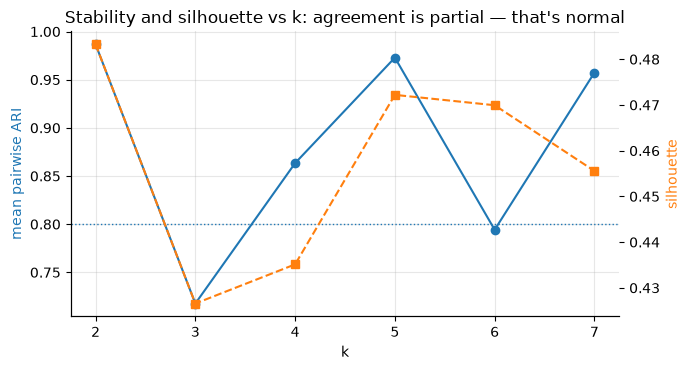

   stability_ARI  silhouette
2          0.987       0.483
3          0.718       0.427
4          0.863       0.435
5          0.973       0.472
6          0.794       0.470
7          0.957       0.456


In [20]:
# --- Solution 2 ---
ks_ex = range(2, 8)
stab_by_k = [bootstrap_stability(X, k, B=8, seed=k) for k in ks_ex]
sil_by_k = [sil[list(ks).index(k)] for k in ks_ex]  # reuse Section 4 silhouettes

fig, ax1 = plt.subplots(figsize=(7, 3.8))
ax1.plot(list(ks_ex), stab_by_k, "o-", color="tab:blue", label="bootstrap stability (ARI)")
ax1.axhline(0.8, color="tab:blue", ls=":", lw=1)
ax1.set_xlabel("k"); ax1.set_ylabel("mean pairwise ARI", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(list(ks_ex), sil_by_k, "s--", color="tab:orange", label="silhouette")
ax2.set_ylabel("silhouette", color="tab:orange")
ax2.grid(False)
ax1.set_title("Stability and silhouette vs k: agreement is partial — that's normal")
plt.show()
print(pd.DataFrame({"stability_ARI": stab_by_k, "silhouette": sil_by_k},
                   index=list(ks_ex)).round(3))
# Several k pass the 0.8 bar and the pattern is non-monotone: stability PRUNES weak k
# values rather than electing a single winner, and it need not agree with silhouette.
# Within the surviving set, nameability and treatment capacity decide — k=4 being both
# stable and nameable is sufficient reason to keep it.

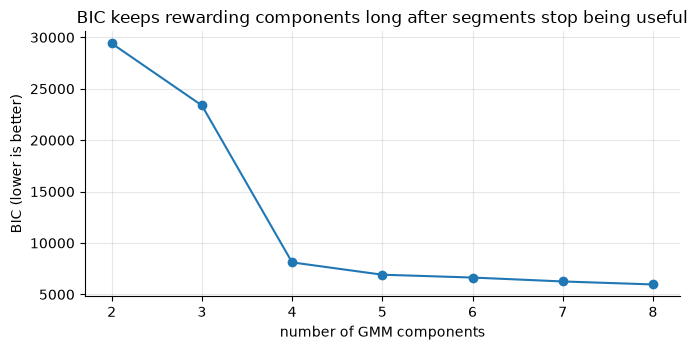

2    29414.0
3    23378.0
4     8112.0
5     6914.0
6     6639.0
7     6258.0
8     5967.0
Name: BIC, dtype: float64


In [21]:
# --- Solution 3 ---
ns = range(2, 9)
bics = [GaussianMixture(n_components=n, covariance_type="full", n_init=3,
                        random_state=42).fit(X).bic(X) for n in ns]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(list(ns), bics, "o-")
ax.set_xlabel("number of GMM components"); ax.set_ylabel("BIC (lower is better)")
ax.set_title("BIC keeps rewarding components long after segments stop being useful")
plt.show()
print(pd.Series(bics, index=list(ns), name="BIC").round(0))
# BIC optimizes out-of-sample DENSITY fit. Behavioral data is non-Gaussian (skewed, bounded),
# so the mixture uses extra components to tile one skewed behavioral group with several
# Gaussians. More components keep improving likelihood while adding nothing actionable.
# BIC bounds the plausible range from above poorly; stability + nameability still decide.
# (If BIC had a clean minimum at a small n here, it's because our simulation IS a mixture
# of near-lognormals — real data is rarely so kind.)